# 3-D star tests: luminosity and slices

Reads the output of the two decks of `docs/vet_clean/STARS.md`:
`inputs/stars/star3d_sp.athinput` (spherical-polar wedge, BSG) and
`star3d_cs.athinput` (cubed sphere, RSG). Needs numpy and matplotlib only.

Set `RUNS` to your run directories (the directory given to `-d`, or where you started the
run). A run that is not there is skipped.

In [1]:
import glob, os, re
import numpy as np
import matplotlib.pyplot as plt

RUNS = {'sp': os.environ.get('STAR3D_SP', 'run_sp'),   # directory of the star3d_sp run
        'cs': os.environ.get('STAR3D_CS', 'run_cs')}   # directory of the star3d_cs run
RSUN = 6.957e10
DAY = 86400.0
RMAX_PLOT = {'sp': None, 'cs': 1200.0}   # slice plots out to this radius [Rsun] (None: whole mesh)
import sys; sys.path.insert(0, os.path.abspath(os.path.join(os.environ.get('ATHENAK', '../../..'), 'tests/vet_clean/notebooks')))
try:                                  # the suite's plot style (optional)
    import nbutil; nbutil.style()
except ImportError:
    pass
plt.rcParams['axes.titlesize'] = 11; plt.rcParams['figure.titlesize'] = 14
plt.rcParams['figure.dpi'] = 72   # keeps the saved notebook small

## Readers

`read_hst` takes the column names from the header line `#  [1]=time  [2]=dt ...`, so it
does not depend on the column order. `read_bin` reads one AthenaK `.bin` dump (format 1.2,
with the true cell-centre coordinates of each MeshBlock) into a list of MeshBlocks.

In [2]:
def read_hst(path):
    """{column name: array} of a .hst file (names from its last '#  [n]=name' line)."""
    hdr = [l for l in open(path) if l.startswith('#') and '[' in l][-1]
    names = [m.group(2) for m in re.finditer(r'\[(\d+)\]=(\S+)', hdr)]
    a = np.atleast_2d(np.loadtxt(path))
    a = a[np.unique(a[:, 0], return_index=True)[1]]   # a restarted run repeats rows
    return {n: a[:, i] for i, n in enumerate(names)}


def read_bin(path):
    """One .bin dump: dict with 'time', 'cycle', 'vars', 'deck' (text) and 'blocks', a list
    (in MeshBlock id order) of dicts: lx (logical location), x1v, x2v, x3v (cell centres),
    and one (nx3, nx2, nx1) array per variable."""
    with open(path, 'rb') as fp:
        size = os.fstat(fp.fileno()).st_size
        assert fp.readline().split()[0] == b'Athena', path
        npre = int(fp.readline().split(b'=')[-1])
        par = {}
        for _ in range(npre - 1):
            k, v = [x.strip() for x in fp.readline().decode().split('=')]
            par[k] = v
        coords = int(par.get('coordinate arrays', '0')) == 1
        lsz, vsz = int(par['size of location']), int(par['size of variable'])
        fp.readline()
        names = fp.readline().decode().split()[1:]
        deck = fp.read(int(fp.readline().split(b'=')[-1])).decode(errors='replace')
        ldt = np.float64 if lsz == 8 else np.float32
        vdt = np.float64 if vsz == 8 else np.float32
        blocks = []
        while fp.tell() < size:
            ind = np.frombuffer(fp.read(24), dtype=np.int32)
            lx = np.frombuffer(fp.read(16), dtype=np.int32)
            ext = np.frombuffer(fp.read(6*lsz), dtype=ldt)
            n1, n2, n3 = ind[1]-ind[0]+1, ind[3]-ind[2]+1, ind[5]-ind[4]+1
            b = {'lx': lx[:3].copy(), 'ext': ext.copy()}
            if coords:
                for d, n in (('1', n1), ('2', n2), ('3', n3)):
                    b['x%sf' % d] = np.fromfile(fp, dtype=ldt, count=n + 1)
                    b['x%sv' % d] = np.fromfile(fp, dtype=ldt, count=n)
            else:
                for d, n, lo, hi in (('1', n1, ext[0], ext[1]), ('2', n2, ext[2], ext[3]),
                                     ('3', n3, ext[4], ext[5])):
                    b['x%sf' % d] = lo + np.arange(n + 1)*(hi - lo)/n
                    b['x%sv' % d] = 0.5*(b['x%sf' % d][1:] + b['x%sf' % d][:-1])
            a = np.fromfile(fp, dtype=vdt, count=n1*n2*n3*len(names))
            a = a.reshape(len(names), n3, n2, n1)
            for i, n in enumerate(names):
                b[n] = a[i]
            blocks.append(b)
    return {'time': float(par['time']), 'cycle': int(par['cycle']), 'vars': names,
            'deck': deck, 'blocks': blocks}


def assemble(dump, var):
    """Global array of var: (nx3, nx2, nx1) on the sp wedge, (6, nx3, nx2, nx1) on the cubed
    sphere (MeshBlocks are written panel by panel, so panel = block index // blocks per
    panel), plus the radial cell faces x1f (one MeshBlock spans the whole radius)."""
    bl = dump['blocks']
    n3, n2, n1 = bl[0][var].shape
    cs = re.search(r'^\s*use_cubed_sphere\s*=\s*(true|1)', dump['deck'], re.M) is not None
    npan = 6 if cs else 1
    per = len(bl)//npan
    L2 = max(b['lx'][1] for b in bl) + 1
    L3 = max(b['lx'][2] for b in bl) + 1
    out = np.zeros((npan, L3*n3, L2*n2, n1))
    for m, b in enumerate(bl):
        p = m//per
        j0, k0 = b['lx'][1]*n2, b['lx'][2]*n3
        out[p, k0:k0+n3, j0:j0+n2, :] = b[var]
    return (out if cs else out[0]), bl[0]['x1f'], cs

## Luminosity vs time

`L_top` is the luminosity through the outer boundary, `L_in` the luminosity the inner
boundary feeds in, `L_bot` the radiative luminosity through the innermost faces (all in
erg/s; [OUTPUTS.md](../OUTPUTS.md) lists every `user.hst` column). A healthy start shows
`L_top/L_in` relaxing from its initial value without spikes.

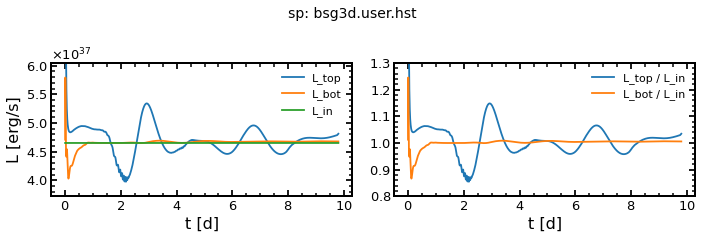

sp: 2787 rows, t = 9.8 d; last L_in 4.6512e+37, L_top 4.8121e+37, L_top/L_in 1.0346 (range over the last half 0.9580 .. 1.0658)
   run_sp.log: CLEAN WARNING lines 0, FATAL 0


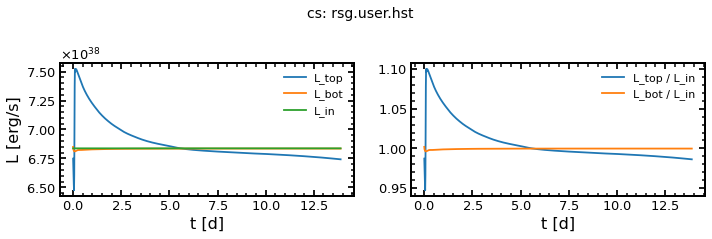

cs: 1201 rows, t = 13.89 d; last L_in 6.8371e+38, L_top 6.7422e+38, L_top/L_in 0.9861 (range over the last half 0.9861 .. 0.9967)
   run_cs.log: CLEAN WARNING lines 0, FATAL 0


In [3]:
def lum_plot(key, d):
    hs = sorted(glob.glob(os.path.join(d, '*.user.hst')))
    if not hs:
        print(key, ': no user.hst in', d); return None
    h = read_hst(hs[0])
    t = h['time']/DAY
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
    for c in ('L_top', 'L_bot', 'L_in'):
        if c in h:
            ax[0].plot(t, h[c], label=c)
    ax[0].set_xlabel('t [d]'); ax[0].set_ylabel('L [erg/s]'); ax[0].legend()
    ax[1].plot(t, h['L_top']/h['L_in'], label='L_top / L_in')
    if 'L_bot' in h:
        ax[1].plot(t, h['L_bot']/h['L_in'], label='L_bot / L_in')
    ax[1].set_xlabel('t [d]'); ax[1].legend()
    if key == 'sp':                       # (its start-up spike of L_top is off the scale)
        ax[1].set_ylim(0.8, 1.3); ax[0].set_ylim(0.8*h['L_in'][-1], 1.3*h['L_in'][-1])
    fig.suptitle('%s: %s' % (key, os.path.basename(hs[0])))
    fig.tight_layout(); plt.show()
    n = len(t)
    print('%s: %d rows, t = %.4g d; last L_in %.4e, L_top %.4e, L_top/L_in %.4f '
          '(range over the last half %.4f .. %.4f)' % (key, n, t[-1], h['L_in'][-1],
          h['L_top'][-1], h['L_top'][-1]/h['L_in'][-1],
          np.min(h['L_top'][n//2:]/h['L_in'][n//2:]), np.max(h['L_top'][n//2:]/h['L_in'][n//2:])))
    # the run's stdout: run_sp.log next to run_sp/ (STARS.md), or a file 'log' inside it
    for lg in glob.glob(os.path.normpath(d) + '.log') + glob.glob(os.path.join(d, 'log')):
        txt = open(lg, errors='replace').read()
        print('   %s: CLEAN WARNING lines %d, FATAL %d' % (os.path.basename(lg),
              txt.count('CLEAN WARNING'), txt.count('FATAL')))
    return h

hst = {k: lum_plot(k, d) for k, d in RUNS.items() if os.path.isdir(d)}

## Slices

Density contrast `rho / <rho>_shell - 1` (the convection pattern) and the radiation energy
density `E` of the last dump, in a meridional plane and in the equatorial plane.

- sp wedge (theta from pi/3 to 2 pi/3, phi from 0 to pi/3): the meridional plane is the
  middle phi column, the equatorial plane the middle theta row.
- cubed sphere: the equatorial plane (z = 0) runs through panels 0, 1, 2, 4 at eta = 0, the
  meridional plane (y = 0) through panels 0, 3, 2, 5 at xi = 0 (the two middle cells are
  averaged).

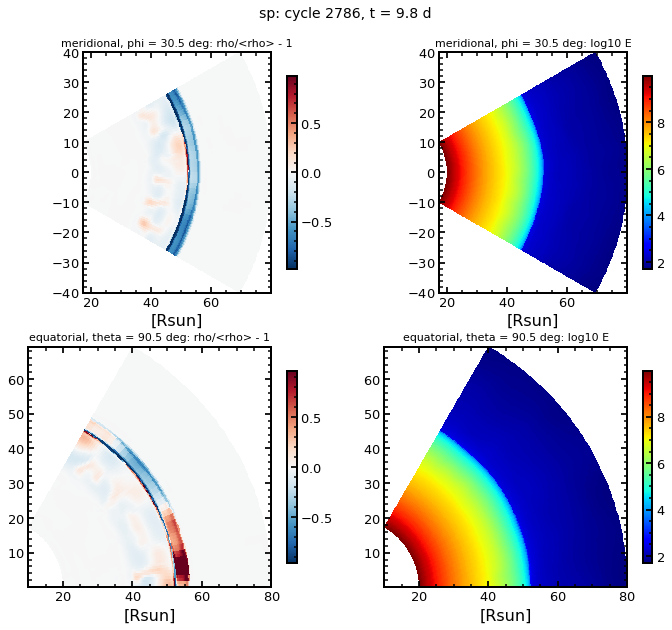

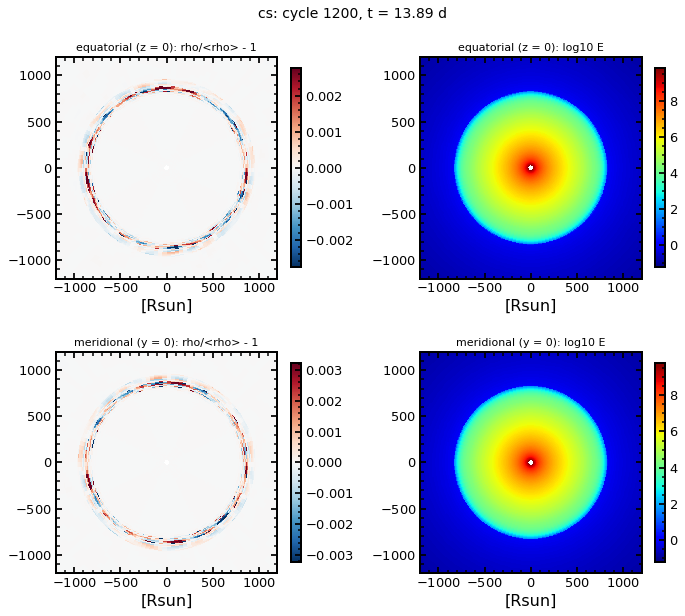

In [4]:
FRAME = {0: ((0, 1, 0), (0, 0, 1), (1, 0, 0)), 1: ((-1, 0, 0), (0, 0, 1), (0, 1, 0)),
         2: ((0, -1, 0), (0, 0, 1), (-1, 0, 0)), 3: ((0, 1, 0), (-1, 0, 0), (0, 0, 1)),
         4: ((1, 0, 0), (0, 0, 1), (0, -1, 0)), 5: ((0, 1, 0), (1, 0, 0), (0, 0, -1))}

def panel_dir(p, xi, eta):
    """Unit vectors of panel p at angles xi, eta (radians), as in coordinates/cubed_sphere.hpp."""
    a, b, n = (np.array(v, float) for v in FRAME[p])
    x, y = np.tan(xi), np.tan(eta)
    q = a[:, None]*x + b[:, None]*y + n[:, None]
    return q/np.sqrt(1 + x*x + y*y)

def contrast(f):
    """rho / <rho>_shell - 1 (shell mean over all lateral cells of the array)."""
    ax = tuple(range(f.ndim - 1))
    return f/f.mean(axis=ax, keepdims=True) - 1

def planes(d):
    """[(title, X, Y, {name: 2-D field})] in units of Rsun for the last dumps of run dir d."""
    hw = sorted(glob.glob(os.path.join(d, '**', '*.hydro_w.*.bin'), recursive=True))
    m1 = sorted(glob.glob(os.path.join(d, '**', '*.vet.*.bin'), recursive=True))
    if not hw or not m1:
        return None, []
    dh, dm = read_bin(hw[-1]), read_bin(m1[-1])
    rho, r, cs = assemble(dh, 'dens')
    E, _, _ = assemble(dm, 'vet_e')
    drho = contrast(rho)
    rf = r/RSUN                       # radial faces
    r = 0.5*(rf[1:] + rf[:-1])        # (approximate) radial centres for the sp plots
    out = []
    if not cs:   # (nx3 = phi, nx2 = theta, nx1 = r); x2v, x3v from the blocks
        th = np.unique(np.concatenate([b['x2v'] for b in dh['blocks']]))
        ph = np.unique(np.concatenate([b['x3v'] for b in dh['blocks']]))
        k, j = len(ph)//2, len(th)//2
        R, T = np.meshgrid(r, th)
        out.append(('meridional, phi = %.1f deg' % np.degrees(ph[k]), R*np.sin(T), R*np.cos(T),
                    {'drho': drho[k], 'log E': np.log10(E[k])}))
        R, P = np.meshgrid(r, ph)
        out.append(('equatorial, theta = %.1f deg' % np.degrees(th[j]), R*np.cos(P), R*np.sin(P),
                    {'drho': drho[:, j], 'log E': np.log10(E[:, j])}))
    else:        # (6, nx3 = eta, nx2 = xi, nx1 = r)
        n = rho.shape[1]
        edg = np.linspace(-np.pi/4, np.pi/4, n + 1)   # cell edges in xi / eta
        def ring(pans, cut):
            X, Y, F, G = [], [], [], []
            for p in pans:
                if cut == 'eta0':   # eta = 0: rows k = n/2-1, n/2
                    q = panel_dir(p, edg, np.zeros(n + 1)); f, g = drho[p, n//2-1:n//2+1].mean(0), E[p, n//2-1:n//2+1].mean(0)
                else:               # xi = 0: columns j = n/2-1, n/2
                    q = panel_dir(p, np.zeros(n + 1), edg); f, g = drho[p, :, n//2-1:n//2+1].mean(1), E[p, :, n//2-1:n//2+1].mean(1)
                X.append(q[0][:, None]*rf); Y.append(q[1 if cut == 'eta0' else 2][:, None]*rf)
                F.append(f); G.append(np.log10(g))
            return X, Y, {'drho': F, 'log E': G}
        X, Y, F = ring((0, 1, 2, 4), 'eta0'); out.append(('equatorial (z = 0)', X, Y, F))
        X, Y, F = ring((0, 3, 2, 5), 'xi0'); out.append(('meridional (y = 0)', X, Y, F))
    return dh, out

def slice_plot(key, d):
    dh, pl = planes(d)
    if dh is None:
        print(key, ': no hydro_w / m1 dumps in', d); return
    fig, axs = plt.subplots(len(pl), 2, figsize=(10, 4.4*len(pl)))
    for row, (title, X, Y, F) in zip(axs, pl):
        for ax, name in zip(row, ('drho', 'log E')):
            Xs, Ys, Fs = (X, Y, F[name]) if isinstance(X, list) else ([X], [Y], [F[name]])
            if name == 'drho':
                v = max(np.percentile(np.abs(np.concatenate([f.ravel() for f in Fs])), 99), 1e-6)
                kw = dict(cmap='RdBu_r', vmin=-v, vmax=v)
            else:
                kw = dict(cmap='jet', vmin=min(f.min() for f in Fs), vmax=max(f.max() for f in Fs))
            for x, y, f in zip(Xs, Ys, Fs):
                im = ax.pcolormesh(x, y, f, shading='flat' if isinstance(X, list) else 'auto', **kw)
            if RMAX_PLOT.get(key):
                lim = RMAX_PLOT[key]
                ax.set_xlim(max(ax.get_xlim()[0], -lim), min(ax.get_xlim()[1], lim))
                ax.set_ylim(max(ax.get_ylim()[0], -lim), min(ax.get_ylim()[1], lim))
            ax.set_aspect('equal'); ax.set_title('%s: %s' % (title, 'rho/<rho> - 1' if name == 'drho' else 'log10 E'))
            ax.set_xlabel('[Rsun]'); fig.colorbar(im, ax=ax, shrink=0.8)
    fig.suptitle('%s: cycle %d, t = %.4g d' % (key, dh['cycle'], dh['time']/DAY))
    fig.tight_layout(); plt.show()

for k, d in RUNS.items():
    if os.path.isdir(d):
        slice_plot(k, d)

## Shell-averaged profiles

Radial profiles of the shell-mean density and radiation energy density of the first and
last dump: the envelope should stay close to its initial structure over a short test.

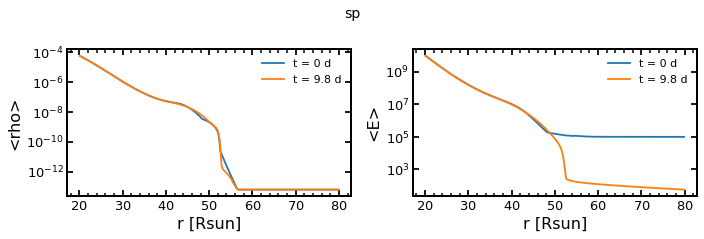

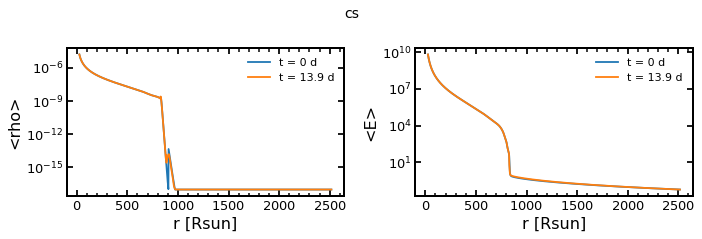

In [5]:
def profiles(key, d):
    hw = sorted(glob.glob(os.path.join(d, '**', '*.hydro_w.*.bin'), recursive=True))
    m1 = sorted(glob.glob(os.path.join(d, '**', '*.vet.*.bin'), recursive=True))
    if not hw or not m1:
        return
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
    for fh, fm in ((hw[0], m1[0]), (hw[-1], m1[-1])):
        dh, dm = read_bin(fh), read_bin(fm)
        rho, rf, cs = assemble(dh, 'dens'); E, _, _ = assemble(dm, 'vet_e')
        r = 0.5*(rf[1:] + rf[:-1])
        axes = tuple(range(rho.ndim - 1))
        lab = 't = %.3g d' % (dh['time']/DAY)
        ax[0].semilogy(r/RSUN, rho.mean(axis=axes), label=lab)
        ax[1].semilogy(r/RSUN, E.mean(axis=axes), label=lab)
    ax[0].set_ylabel('<rho>'); ax[1].set_ylabel('<E>')
    for a in ax:
        a.set_xlabel('r [Rsun]'); a.legend()
    fig.suptitle(key); fig.tight_layout(); plt.show()

for k, d in RUNS.items():
    if os.path.isdir(d):
        profiles(k, d)